             CRIM          RM       LSTAT         TAX        MEDV
count  200.000000  200.000000  200.000000  200.000000  200.000000
mean     4.840062    6.521876   16.578838  419.105000   27.161127
std      2.948914    1.465006    8.604646  145.035029    9.873752
min      0.055221    4.025308    2.303454  200.000000    2.348589
25%      2.285824    5.307313    9.154569  292.500000   20.336537
50%      4.944863    6.708199   16.711185  420.500000   27.312084
75%      7.568596    7.710997   24.711217  534.000000   33.944055
max      9.868869    8.952526   29.992095  692.000000   48.237074
CRIM    -0.116502
RM       0.815928
LSTAT   -0.594228
TAX     -0.139404
MEDV     1.000000
Name: MEDV, dtype: float64
Coefficients: {'CRIM': np.float64(-0.3359326937926411), 'RM': np.float64(5.042160579756144), 'LSTAT': np.float64(-0.5916653707371403), 'TAX': np.float64(-0.011956282347770575)}
MAE : 1.6495678898581168
MSE : 4.156537372230824
RMSE: 2.038758782257191
R2  : 0.9577262387774804


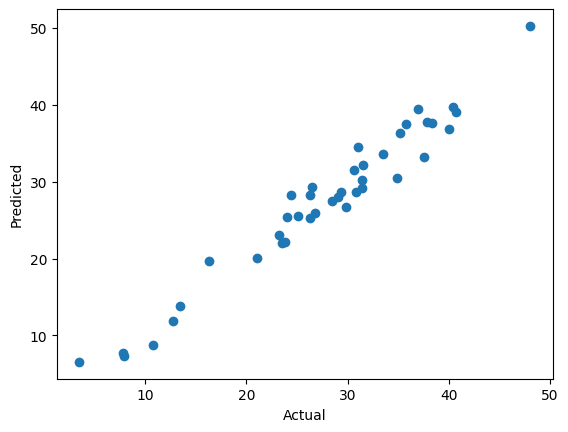

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
n = 200
df = pd.DataFrame({
    "CRIM": np.random.uniform(0, 10, n),
    "RM": np.random.uniform(4, 9, n),
    "LSTAT": np.random.uniform(2, 30, n),
    "TAX": np.random.randint(200, 700, n)})
df["MEDV"] = 5*df["RM"] - 0.6*df["LSTAT"] - 0.3*df["CRIM"] - 0.01*df["TAX"] + 10 + np.random.normal(0, 2, n)

print(df.describe())
print(df.corr()["MEDV"])

X = df.drop("MEDV", axis=1)
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Coefficients:", dict(zip(X.columns, model.coef_)))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
n = 300
df = pd.DataFrame({
    "Pclass": np.random.randint(1, 4, n),
    "Sex": np.random.choice(["male", "female"], n),
    "Age": np.random.randint(1, 70, n).astype(float),
    "Fare": np.random.uniform(5, 200, n)})
df.loc[np.random.choice(n, 30, replace=False), "Age"] = np.nan
score = (df["Sex"] == "female")*2 - df["Pclass"]*0.7 + np.random.normal(0, 1, n)
df["Survived"] = (score > -0.3).astype(int)

print(df.isnull().sum())
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

X = df.drop("Survived", axis=1)
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Pclass       0
Sex          0
Age         30
Fare         0
Survived     0
dtype: int64
Accuracy : 0.85
Precision: 0.8666666666666667
Recall   : 0.8387096774193549
F1-Score : 0.8524590163934426
[[25  4]
 [ 5 26]]


Accuracy : 0.76
Precision: 0.7142857142857143
Recall   : 0.5555555555555556
F1-Score : 0.625
[[56  8]
 [16 20]]
education_num     0.626632
hours_per_week    0.219325
marital_Single    0.124956
age               0.029086
sex_Male          0.000000
dtype: float64


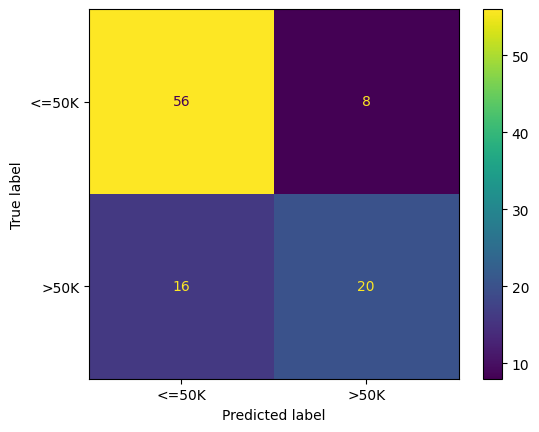

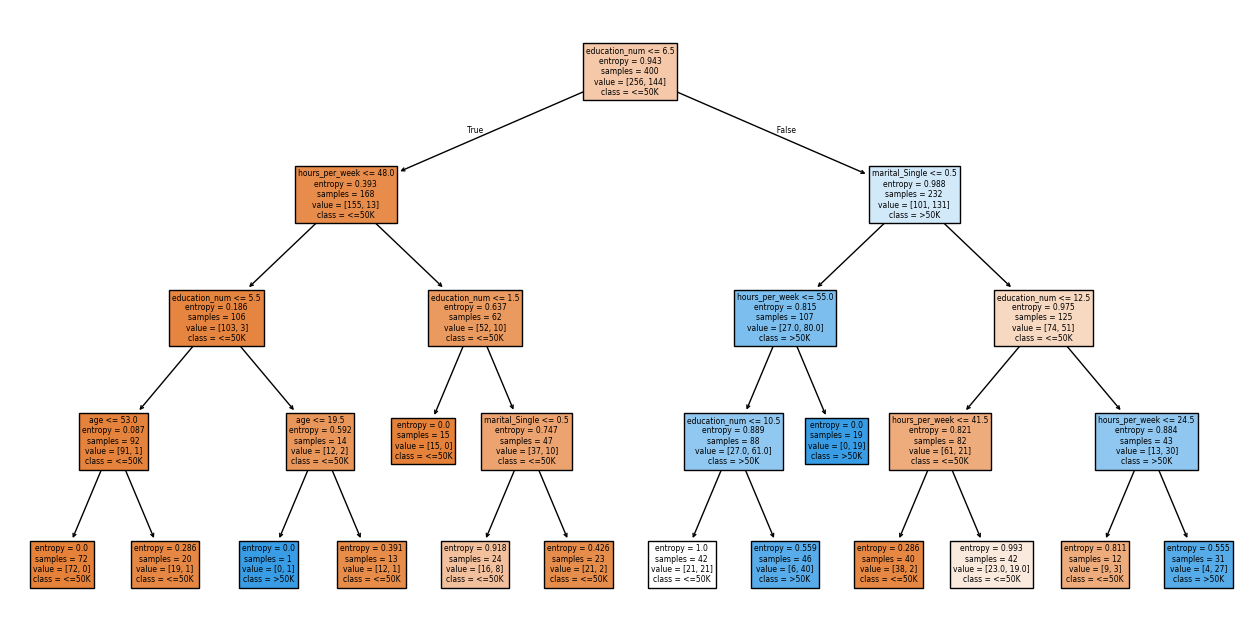

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
n = 500
df = pd.DataFrame({
    "age": np.random.randint(18, 70, n),
    "education_num": np.random.randint(1, 16, n),
    "hours_per_week": np.random.randint(10, 70, n),
    "sex": np.random.choice(["Male", "Female"], n),
    "marital": np.random.choice(["Married", "Single"], n)})
score = df["education_num"]*0.4 + df["hours_per_week"]*0.05 + (df["marital"] == "Married")*2 + np.random.normal(0, 1.5, n)
df["income"] = np.where(score > score.median() + 1, ">50K", "<=50K")

X = pd.get_dummies(df.drop("income", axis=1), drop_first=True)
y = df["income"].map({"<=50K": 0, ">50K": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["<=50K", ">50K"])
plt.show()

plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=list(X.columns), class_names=["<=50K", ">50K"], filled=True)
plt.show()

Accuracy : 0.83
Precision: 0.8064516129032258
Recall   : 0.6944444444444444
F1-Score : 0.746268656716418
[[58  6]
 [11 25]]
education_num     0.441467
hours_per_week    0.261814
age               0.192888
marital_Single    0.077337
sex_Male          0.026495
dtype: float64


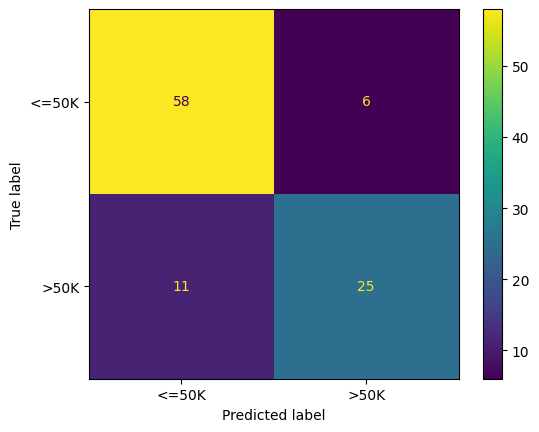

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
n = 500
df = pd.DataFrame({
    "age": np.random.randint(18, 70, n),
    "education_num": np.random.randint(1, 16, n),
    "hours_per_week": np.random.randint(10, 70, n),
    "sex": np.random.choice(["Male", "Female"], n),
    "marital": np.random.choice(["Married", "Single"], n)})
score = df["education_num"]*0.4 + df["hours_per_week"]*0.05 + (df["marital"] == "Married")*2 + np.random.normal(0, 1.5, n)
df["income"] = np.where(score > score.median() + 1, ">50K", "<=50K")

X = pd.get_dummies(df.drop("income", axis=1), drop_first=True)
y = df["income"].map({"<=50K": 0, ">50K": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["<=50K", ">50K"])
plt.show()

Accuracy : 0.77
Precision: 0.696969696969697
Recall   : 0.6388888888888888
F1-Score : 0.6666666666666666
[[54 10]
 [13 23]]
education_num     0.538333
hours_per_week    0.223486
marital_Single    0.131673
age               0.098210
sex_Male          0.008299
dtype: float64


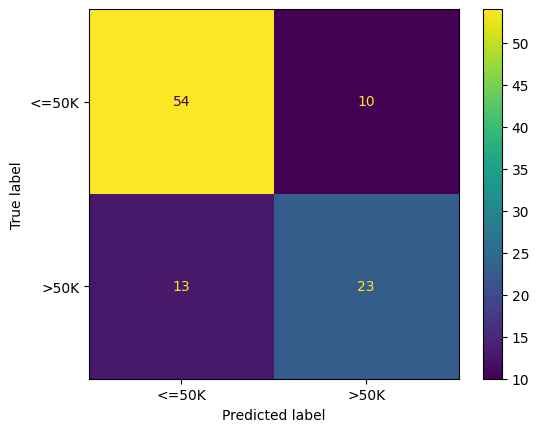

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
n = 500
df = pd.DataFrame({
    "age": np.random.randint(18, 70, n),
    "education_num": np.random.randint(1, 16, n),
    "hours_per_week": np.random.randint(10, 70, n),
    "sex": np.random.choice(["Male", "Female"], n),
    "marital": np.random.choice(["Married", "Single"], n)})
score = df["education_num"]*0.4 + df["hours_per_week"]*0.05 + (df["marital"] == "Married")*2 + np.random.normal(0, 1.5, n)
df["income"] = np.where(score > score.median() + 1, ">50K", "<=50K")

X = pd.get_dummies(df.drop("income", axis=1), drop_first=True)
y = df["income"].map({"<=50K": 0, ">50K": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["<=50K", ">50K"])
plt.show()

# If the examiner says “AdaBoost”, use from sklearn.ensemble import AdaBoostClassifier and AdaBoostClassifier(n_estimators=100, random_state=42).

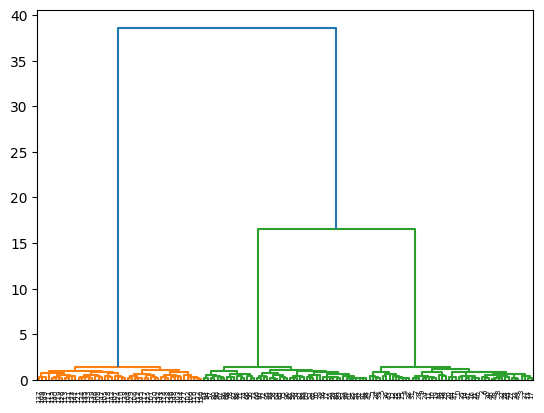

Cluster
1    50
2    50
0    50
Name: count, dtype: int64
                Fresh          Milk       Grocery        Frozen  \
Cluster                                                           
0        30189.131152  30052.399039  29804.331905  30038.960652   
1         5314.342956   4606.659659   4688.744008   4960.954974   
2        15096.639248  14919.763987  15211.032646  15002.874337   

         Detergents_Paper    Delicassen  
Cluster                                  
0            30165.546068  30489.378259  
1             4843.640401   5535.720970  
2            14748.541991  14827.737948  
Silhouette Score: 0.8263710206538807
Cophenetic Correlation: 0.9198908386013831


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

np.random.seed(42)
cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
data = np.vstack([np.random.normal(m, 1500, (50, 6)) for m in (5000, 15000, 30000)])
df = pd.DataFrame(data, columns=cols)

X = StandardScaler().fit_transform(df)

Z = linkage(X, method="ward", metric="euclidean")
dendrogram(Z)
plt.show()

model = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
df["Cluster"] = model.fit_predict(X)

print(df["Cluster"].value_counts())
print(df.groupby("Cluster").mean())
print("Silhouette Score:", silhouette_score(X, df["Cluster"]))
print("Cophenetic Correlation:", cophenet(Z, pdist(X))[0])